In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. Load the cleaned dataset we created in Phase 1
data_path = Path("../data/processed/omni2_cleaned.csv") if Path("../data/processed").exists() else Path("data/processed/omni2_cleaned.csv")
df = pd.read_csv(data_path, parse_dates=["Timestamp"], index_col="Timestamp")

print(f" Loaded cleaned dataset: {df.shape[0]:,} rows × {df.shape[1]} columns\n")

# 2. Select key scientific features for statistical analysis
key_features = [
    "Scalar_B", "BZ_GSM", "Flow_Speed", 
    "Proton_Density", "Temperature", "Flow_Pressure", 
    "Electric_Field", "Dst_index"
]

# 3. Compute Module S-1 Statistical Measures (Central Tendency, Spread, Shape)
stats_summary = pd.DataFrame(index=key_features)

stats_summary["Mean"] = df[key_features].mean()
stats_summary["Median"] = df[key_features].median()
stats_summary["Std_Dev"] = df[key_features].std()
stats_summary["Variance"] = df[key_features].var()
stats_summary["IQR"] = df[key_features].quantile(0.75) - df[key_features].quantile(0.25)
stats_summary["Skewness"] = df[key_features].skew()
stats_summary["Kurtosis"] = df[key_features].kurtosis()

print(" STATISTICAL SUMMARY (Measures of Central Tendency, Dispersion & Shape):")
stats_summary.round(2)

 Loaded cleaned dataset: 52,584 rows × 12 columns

 STATISTICAL SUMMARY (Measures of Central Tendency, Dispersion & Shape):


,Mean,Median,Std_Dev,Variance,IQR,Skewness,Kurtosis
Scalar_B,5.25,4.70,2.59,6.730000e+00,2.60,2.46,11.86
BZ_GSM,-0.13,-0.20,2.66,7.050000e+00,2.70,0.19,8.07
Flow_Speed,410.32,391.00,85.65,7.335990e+03,116.00,0.94,0.55
Proton_Density,6.31,5.00,4.73,2.236000e+01,4.61,2.80,15.18
Temperature,81711.14,57691.50,78944.20,6.232186e+09,72513.25,4.23,47.95
Flow_Pressure,1.80,1.50,1.24,1.540000e+00,1.07,3.53,25.27
Electric_Field,0.06,0.06,1.13,1.290000e+00,1.08,0.04,13.59
Dst_index,-8.51,-6.00,14.40,2.074300e+02,15.00,-2.09,13.55


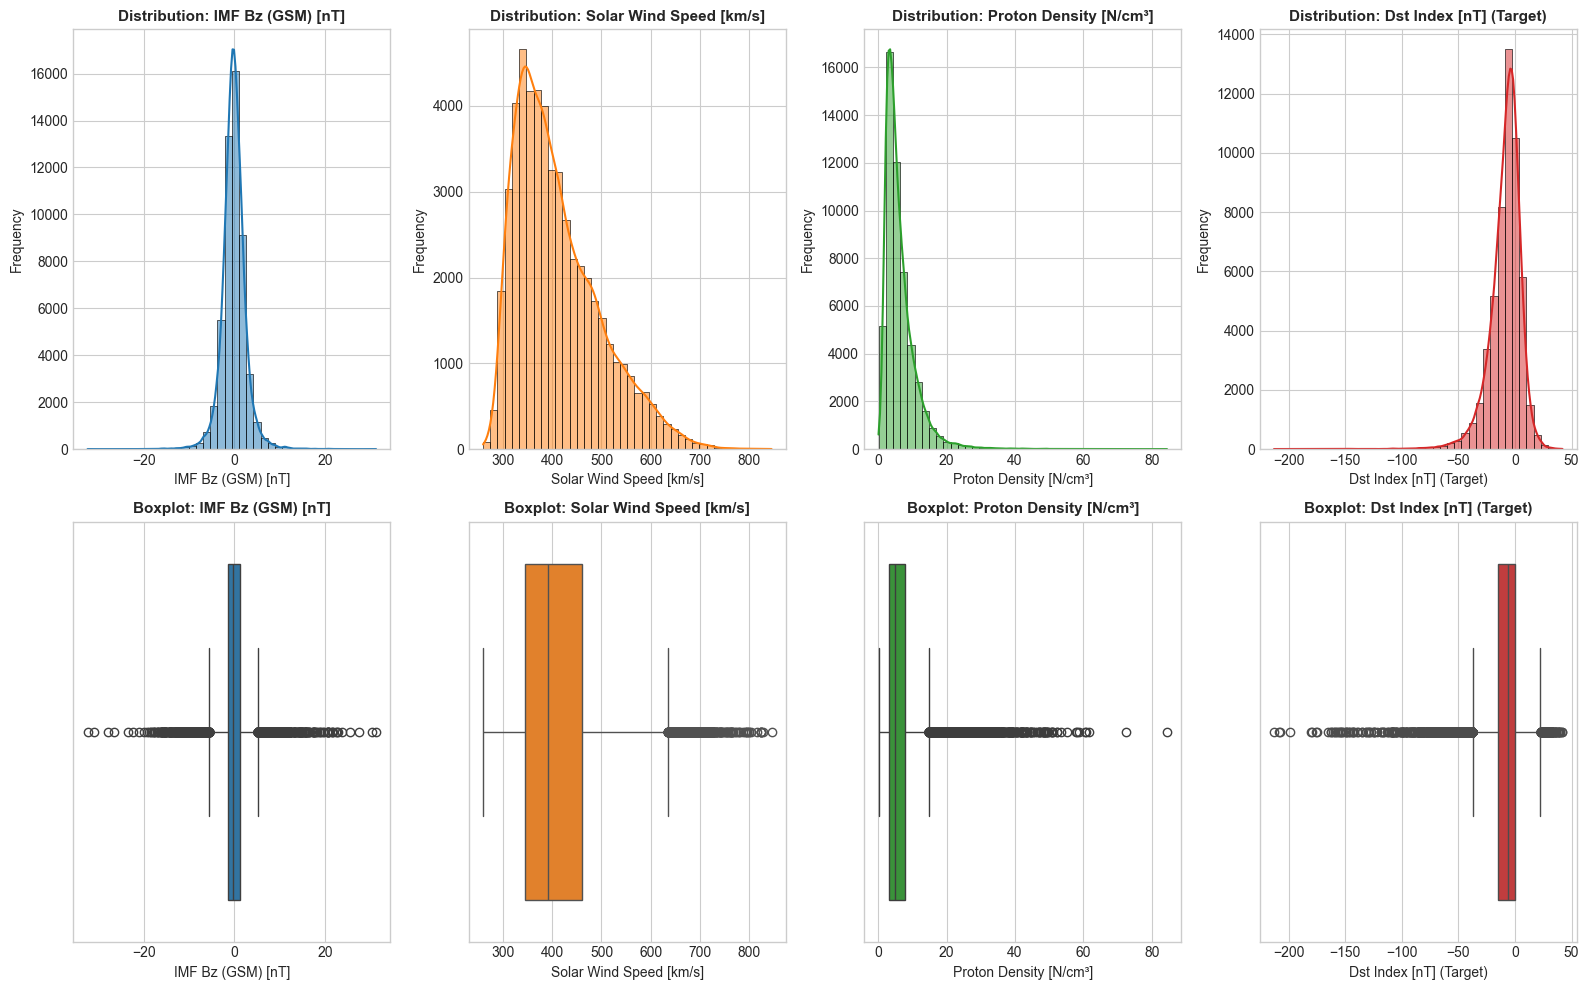

 Distribution and outlier plots successfully rendered!


In [3]:
# Set up a clean, publication-style visualization grid
plt.figure(figsize=(16, 10))
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

plot_features = [
    ("BZ_GSM", "IMF Bz (GSM) [nT]", "#1f77b4"),
    ("Flow_Speed", "Solar Wind Speed [km/s]", "#ff7f0e"),
    ("Proton_Density", "Proton Density [N/cm³]", "#2ca02c"),
    ("Dst_index", "Dst Index [nT] (Target)", "#d62728")
]

for idx, (col, title, color) in enumerate(plot_features, 1):
    # Top row: Histograms with KDE (Kernel Density Estimate)
    plt.subplot(2, 4, idx)
    sns.histplot(df[col], kde=True, color=color, bins=40)
    plt.title(f"Distribution: {title}", fontsize=11, fontweight="bold")
    plt.xlabel(title, fontsize=10)
    plt.ylabel("Frequency", fontsize=10)
    
    # Bottom row: Boxplots to highlight outliers / tails
    plt.subplot(2, 4, idx + 4)
    sns.boxplot(x=df[col], color=color)
    plt.title(f"Boxplot: {title}", fontsize=11, fontweight="bold")
    plt.xlabel(title, fontsize=10)

plt.tight_layout()
plt.show()
print(" Distribution and outlier plots successfully rendered!")

[INFO] Pearson Correlation with Dst_index (Target):
-------------------------------------------------------
  Proton_Density      : +0.313
  BZ_GSM              : +0.280
  BY_GSM              : +0.012
  Flow_Pressure       : +0.009
  BX_GSM              : +0.003
  Scalar_B            : -0.283
  Electric_Field      : -0.290
  Temperature         : -0.347
  Flow_Speed          : -0.480
  Kp_index            : -0.518
  AE_index            : -0.544
-------------------------------------------------------


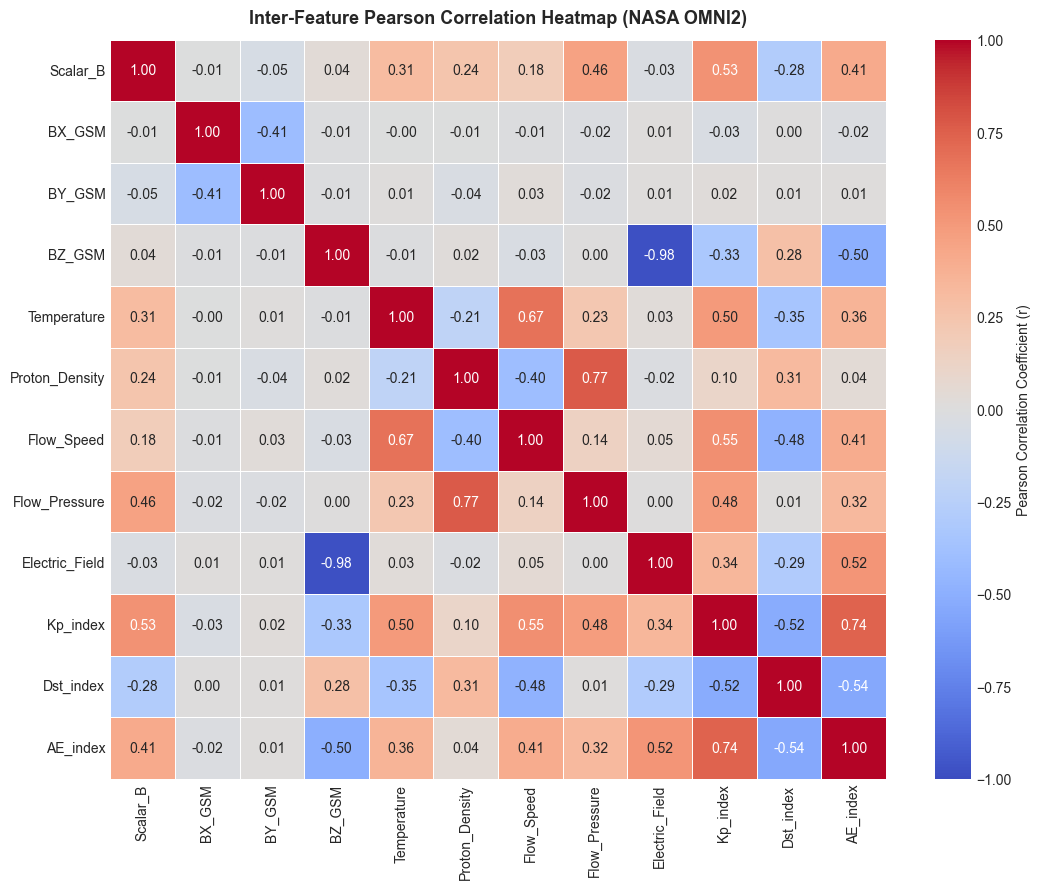

[INFO] Correlation heatmap successfully generated.


In [4]:
#Correlation Matrix & Heatmap

# 1. Compute Pearson correlation matrix for all features against the target Dst
corr_matrix = df.corr(method="pearson")

# 2. Extract and sort correlation specifically with Dst_index
dst_corr = corr_matrix["Dst_index"].sort_values(ascending=False)

print("[INFO] Pearson Correlation with Dst_index (Target):")
print("-" * 55)
for feature, score in dst_corr.items():
    if feature != "Dst_index":
        print(f"  {feature:20s}: {score:+.3f}")
print("-" * 55)

# 3. Render publication-style correlation heatmap
plt.figure(figsize=(11, 9))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation Coefficient (r)"}
)
plt.title("Inter-Feature Pearson Correlation Heatmap (NASA OMNI2)", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

print("[INFO] Correlation heatmap successfully generated.")

[INFO] Extreme Storm Peak Detected:
       Timestamp : 2023-04-24 05:00:00
       Min Dst   : -213.0 nT (Severe G4 Geomagnetic Storm)


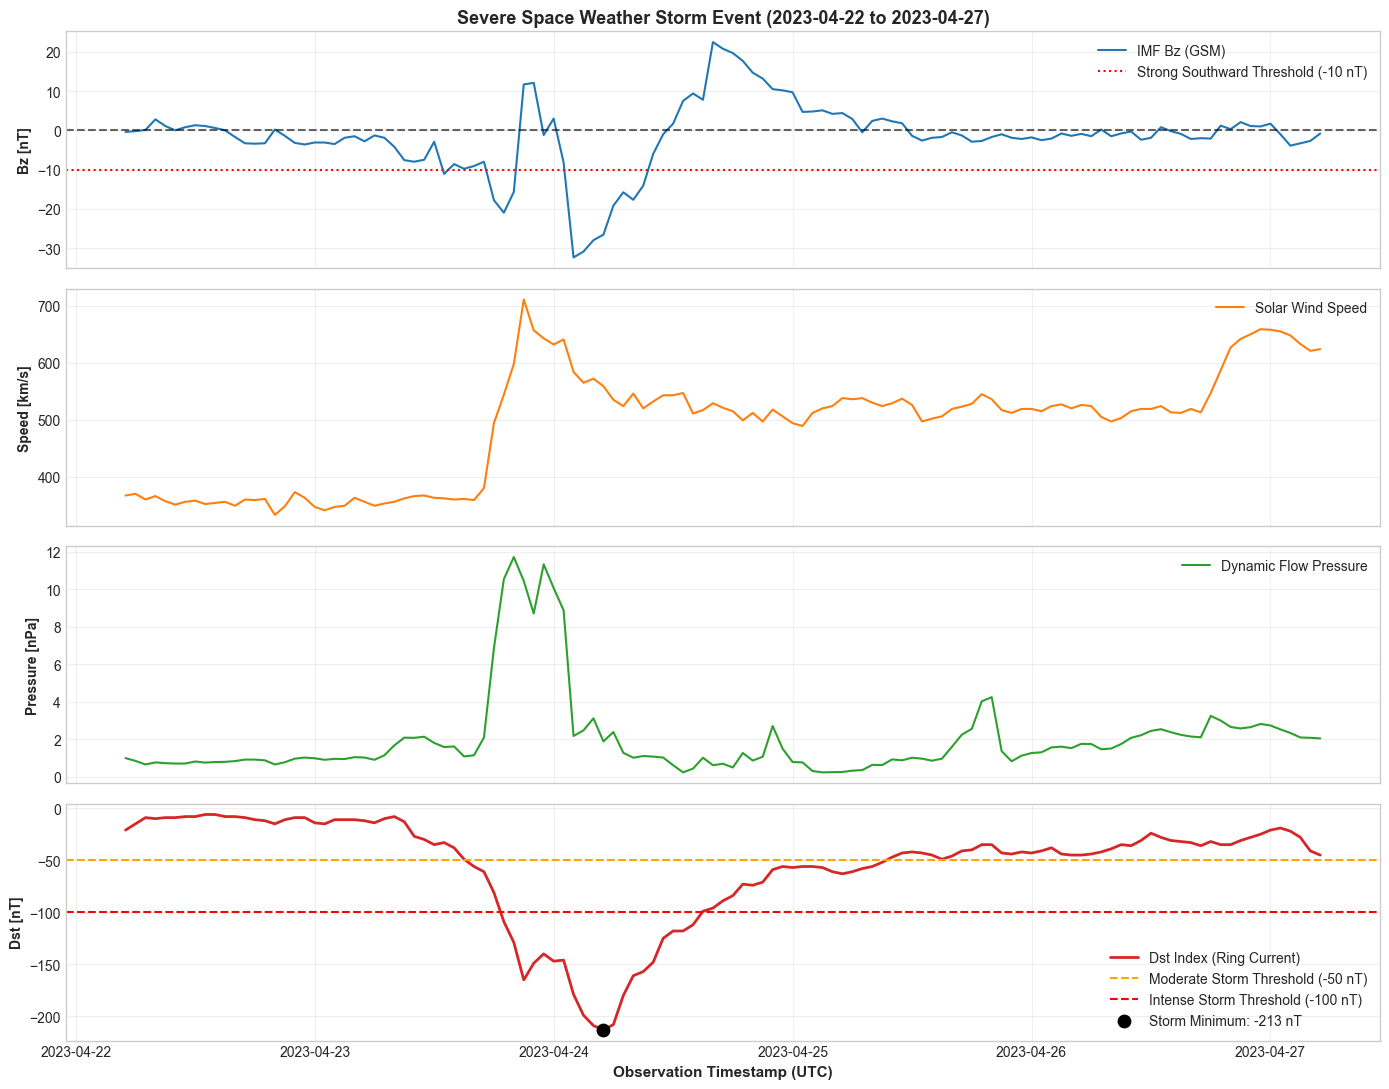

[INFO] Historic storm multi-parameter case study successfully generated.


In [5]:
#The Historic Storm Timeline

# 1. Locate the exact timestamp of the most extreme storm in our 6-year dataset
peak_storm_time = df["Dst_index"].idxmin()
min_dst_val = df.loc[peak_storm_time, "Dst_index"]

print(f"[INFO] Extreme Storm Peak Detected:")
print(f"       Timestamp : {peak_storm_time}")
print(f"       Min Dst   : {min_dst_val:.1f} nT (Severe G4 Geomagnetic Storm)")

# 2. Extract a 5-day window centered around the storm peak
start_window = peak_storm_time - pd.Timedelta(days=2)
end_window = peak_storm_time + pd.Timedelta(days=3)
storm_df = df.loc[start_window:end_window]

# 3. Plot the multi-parameter space weather response
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)

# Panel A: IMF Bz (The Reconnection Driver)
axes[0].plot(storm_df.index, storm_df["BZ_GSM"], color="#1f77b4", linewidth=1.5, label="IMF Bz (GSM)")
axes[0].axhline(0, color="black", linestyle="--", alpha=0.6)
axes[0].axhline(-10, color="red", linestyle=":", label="Strong Southward Threshold (-10 nT)")
axes[0].set_ylabel("Bz [nT]", fontsize=10, fontweight="bold")
axes[0].set_title(f"Severe Space Weather Storm Event ({start_window.date()} to {end_window.date()})", fontsize=13, fontweight="bold")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)

# Panel B: Solar Wind Speed
axes[1].plot(storm_df.index, storm_df["Flow_Speed"], color="#ff7f0e", linewidth=1.5, label="Solar Wind Speed")
axes[1].set_ylabel("Speed [km/s]", fontsize=10, fontweight="bold")
axes[1].legend(loc="upper right")
axes[1].grid(True, alpha=0.3)

# Panel C: Dynamic Flow Pressure
axes[2].plot(storm_df.index, storm_df["Flow_Pressure"], color="#2ca02c", linewidth=1.5, label="Dynamic Flow Pressure")
axes[2].set_ylabel("Pressure [nPa]", fontsize=10, fontweight="bold")
axes[2].legend(loc="upper right")
axes[2].grid(True, alpha=0.3)

# Panel D: Dst Index (The Terrestrial Magnetic Response)
axes[3].plot(storm_df.index, storm_df["Dst_index"], color="#d62728", linewidth=2.0, label="Dst Index (Ring Current)")
axes[3].axhline(-50, color="orange", linestyle="--", label="Moderate Storm Threshold (-50 nT)")
axes[3].axhline(-100, color="red", linestyle="--", label="Intense Storm Threshold (-100 nT)")
axes[3].scatter([peak_storm_time], [min_dst_val], color="black", s=80, zorder=5, label=f"Storm Minimum: {min_dst_val:.0f} nT")
axes[3].set_ylabel("Dst [nT]", fontsize=10, fontweight="bold")
axes[3].set_xlabel("Observation Timestamp (UTC)", fontsize=11, fontweight="bold")
axes[3].legend(loc="lower right")
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("[INFO] Historic storm multi-parameter case study successfully generated.")